# Parse MODIS HDF files with `xarray`

In [1]:
import os
import pathlib
import rasterio
import fiona
import pandas as pd
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd
from rasterio.features import rasterize 


from datetime import datetime

In [2]:
files = list(pathlib.Path('/Users/topcat/projects/prescribed_fires/modis_test_data_proj/').rglob('*.tif'))

In [3]:
us = gpd.read_file('/Users/topcat/Downloads/ne_10m_admin_2_counties/ne_10m_admin_2_counties.shp')
california = us[us.ISO_3166_2 == 'US-06']

In [4]:
us.head()

,FEATURECLA,SCALERANK,ADM2_CODE,ISO_3166_2,ISO_A2,ADM0_SR,NAME,NAME_ALT,NAME_LOCAL,TYPE,...,NAME_PT,NAME_RU,NAME_SV,NAME_TR,NAME_UK,NAME_UR,NAME_VI,NAME_ZH,NAME_ZHT,geometry
0,Admin-2 scale rank,0,USA-53073,US-53,US,1,Whatcom,Whatcom County,None,County,...,Whatcom,Уотком,Whatcom,Whatcom,Вотком,واٹکم کاؤنٹی، واشنگٹن,Whatcom,霍特科姆县,霍特科姆縣,"MULTIPOLYGON (((-122.75302 48.99251, -122.6532..."
1,Admin-2 scale rank,0,USA-53047,US-53,US,1,Okanogan,Okanogan County,None,County,...,Okanogan,Оканоган,Okanogan,Okanogan,Оканоґан,اوکاناگن کاؤنٹی، واشنگٹن,Okanogan,奥卡诺根县,奧卡諾根縣,"POLYGON ((-120.85196 48.99251, -120.67495 48.9..."
2,Admin-2 scale rank,0,USA-53019,US-53,US,1,Ferry,Ferry County,None,County,...,Ferry,Ферри,Ferry,Ferry,Феррі,فیری کاؤنٹی، واشنگٹن,Ferry,费里县,費里縣,"POLYGON ((-118.83688 48.99251, -118.69668 48.9..."
3,Admin-2 scale rank,0,USA-53065,US-53,US,1,Stevens,Stevens County,None,County,...,Stevens,Стивенс,Stevens,Stevens,Стівенс,سٹیونس کاؤنٹی، واشنگٹن,Stevens,史蒂文斯县,史蒂文斯縣,"POLYGON ((-118.21996 48.99251, -118.03723 48.9..."
4,Admin-2 scale rank,0,USA-53051,US-53,US,1,Pend Oreille,Pend Oreille County,None,County,...,Pend Oreille,Панд-Орей,Pend Oreille,Pend Oreille,Понд-Орей,پینڈ اورائل کاؤنٹی، واشنگٹن,Pend Oreille,庞多雷县,龐多雷縣,"POLYGON ((-117.42951 48.99251, -117.37787 48.9..."


In [5]:
def batch_crosswalk(path_template_raster,
                    path_shape,
                    id_var):
        '''
        Create one-to-one relation between pixels and polygon boundaries using one
        raster layer. 
        Returns:
            pandas.DataFrame with indexed data for each cell value and its index
            (or the feature_to_burn) 
        '''

        with rasterio.open(path_template_raster) as src:
            with fiona.open(path_shape, 'r') as shp:
                geoms = [feature['geometry'] for feature in shp]
                index = [feature['properties'][id_var] for feature in shp]

                crosswalk_dict = {}
                for idx, geom in zip(index, geoms):
                    geom_rasterize = rasterize([(geom, 1)],
                                               out_shape=src.shape,
                                               transform=src.transform,
                                               all_touched=True,
                                               fill=0,
                                               dtype='uint8')

                    crosswalk_dict[idx] = np.where(geom_rasterize == 1)

        return crosswalk_dict

crosswalk = batch_crosswalk(path_shape='/Users/topcat/Downloads/ne_10m_admin_2_counties/ne_10m_admin_2_counties.shp',
                            path_template_raster='/Users/topcat/projects/prescribed_fires/modis_test_data_proj/MOD14A1.A2020233.mosaic.006.2021348212951.psmc_000501691202.MaxFRP_1-MaxFRP.tif',
                            id_var='ADM2_CODE'
                           )

In [161]:
from rasterio.plot import show

df_list = []
for file in files:   
    with rasterio.open(file) as src: 
        timestamp_seed = datetime.strptime(str(file).split('.')[1][1:9], '%Y%j')
        days = int(re.search('[\d]', file.name.split('.')[-2]).group(0))
        timestamp = timestamp_seed + pd.DateOffset(days)
        
        data = src.read(1) * 0.1
        #data = np.where(data == 0, np.nan, data)
        
        list_geoms = []
        for key, value in crosswalk.items():
            mean_geom = np.nanmean(data[value])
            list_geoms.append(mean_geom)
                
        mean_array =  np.asarray(list_geoms)
        df = pd.DataFrame(data = [mean_array],
                          columns = crosswalk.keys(),
                          index=[timestamp])
        df_list.append(df)

/var/folders/_l/ss1_csv9279c905rclvs4f840000gn/T/ipykernel_19044/2956409241.py:15: RuntimeWarning: Mean of empty slice
  mean_geom = np.nanmean(data[value])


In [162]:
extract_concat = pd.concat(df_list)

# Clean concatenation index
#new_index = pd.DatetimeIndex(pd.date_range(extract_concat.index.min(), extract_concat.index.max(), freq='1d'))
#df_reindex = df_grouped.reindex(new_index)

# Rename variables and start reshape
extract_concat.reset_index(drop=False, inplace=True)
extract_concat.rename(columns={'index': 'timestamp'}, inplace=True)
df_reindex = extract_concat.melt(id_vars=['timestamp'], var_name = 'geoid')
df_reindex.rename(columns={'value': 'fire_temp'}, inplace=True)
df_reindex = df_reindex[~df_reindex['fire_temp'].isna()]

In [193]:
df_reindex = df_reindex.assign(
    state_fips = df_reindex.geoid.apply(lambda x: x.split('-')[1][0:2]),
    county_fips = df_reindex.geoid.apply(lambda x: x.split('-')[1])
)
california_temp = df_reindex[df_reindex.state_fips == '06']

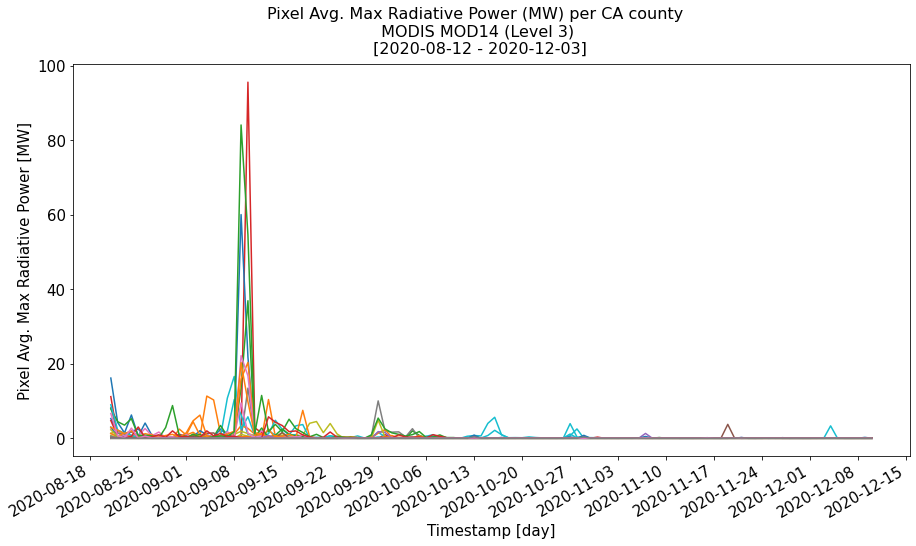

In [242]:
import matplotlib.dates as mdates
import matplotlib
matplotlib.rcParams.update({'font.size': 15})

cali_plot_pivot = california_temp.pivot_table(index=["timestamp"], 
                    columns='county_fips', 
                    values='fire_temp')
fig, ax = plt.subplots(figsize=(15, 8), facecolor='white')
cali_plot_pivot.plot(xlabel="Timestamp [day]", 
                     ylabel="Pixel Avg. Max Radiative Power [MW]",
                     x_compat=True,
                     legend=False,
                     ax=ax)
ax.xaxis.set_major_locator(mdates.WeekdayLocator())
fig.suptitle('Pixel Avg. Max Radiative Power (MW) per CA county \n MODIS MOD14 (Level 3) \n [2020-08-12 - 2020-12-03]', fontsize=16)
fig.savefig('timeseries_complex.png')

<AxesSubplot:xlabel='timestamp'>

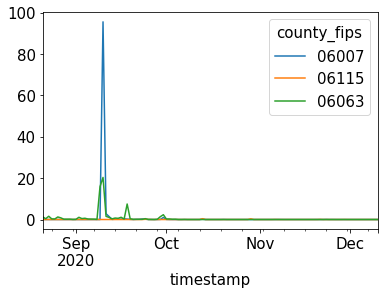

In [241]:
ncomplex = ['06007', '06115', '06063']
cali_plot_pivot[ncomplex].plot()

In [163]:
df_reshape = df_reindex.groupby(['geoid'], as_index=False).fire_temp.sum()

In [164]:
calfire = california.merge(df_reshape, right_on='geoid', left_on='ADM2_CODE')

In [236]:
california[california.NAME.isin(['Yuba', 'Butte', 'Plumas'])].

,FEATURECLA,SCALERANK,ADM2_CODE,ISO_3166_2,ISO_A2,ADM0_SR,NAME,NAME_ALT,NAME_LOCAL,TYPE,...,NAME_PT,NAME_RU,NAME_SV,NAME_TR,NAME_UK,NAME_UR,NAME_VI,NAME_ZH,NAME_ZHT,geometry
1589,Admin-2 scale rank,0,USA-06007,US-06,US,1,Butte,Butte County,None,County,...,Butte,Бьютт,Butte,Butte,Б'ютт,بوٹ کاؤنٹی، کیلیفورنیا,Butte,比尤特县,布尤特郡,"POLYGON ((-121.07589 39.59776, -121.07803 39.5..."
1590,Admin-2 scale rank,0,USA-06115,US-06,US,1,Yuba,Yuba County,None,County,...,Yuba,Юба,Yuba,Yuba,Юба,یبا کاؤنٹی، کیلی فورنیا,Yuba,尤巴县,尤巴县,"POLYGON ((-121.61217 39.30073, -121.60910 39.3..."
1595,Admin-2 scale rank,0,USA-06063,US-06,US,1,Plumas,Plumas County,None,County,...,Plumas,Плумас,Plumas,Plumas,Плумас,پلومس کاؤنٹی، کیلیفورنیا,Plumas,普卢默斯县,普盧默斯縣,"POLYGON ((-121.07589 39.59776, -121.08795 39.6..."


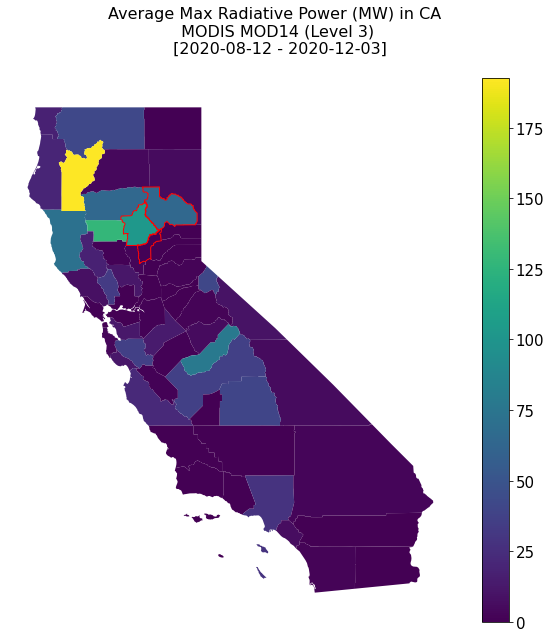

In [243]:
fig, ax = plt.subplots(figsize=(10, 10),  facecolor='white')
calfire.plot(column='fire_temp', ax=ax, legend=True)
california[california.NAME.isin(['Yuba', 'Butte', 'Plumas'])].plot(facecolor='none', edgecolor='red', ax=ax)
ax.set_axis_off()
fig.suptitle('Average Max Radiative Power (MW) in CA \n MODIS MOD14 (Level 3) \n [2020-08-12 - 2020-12-03]', fontsize=16)
fig.savefig('map_complex.png')

In [26]:
fires = gpd.read_file('/Users/topcat/Downloads/Interagency_Fire_Perimeter_History_-_All_Years/InteragencyFirePerimeterHistory.shp')

In [31]:
fires[fires.FIRE_YEAR_ == 2020].AGENCY.unique()

array(['CDF', 'DOD', 'CCO', 'LRA', 'USFS', 'AICC', 'FWS', 'BLM'],
      dtype=object)

In [25]:
fires.fire_date[fires.fire_date.dt.year < 2020].sort_values()

24233   1984-01-26
2679    1984-02-21
23507   1984-02-26
2697    1984-03-29
23521   1984-03-29
           ...    
28214   2019-12-16
28316   2019-12-19
27965   2019-12-24
27975   2019-12-24
27973   2019-12-24
Name: fire_date, Length: 28584, dtype: datetime64[ns]

In [327]:
fires[fires.Incid_Name.str.contains('NORTH')]

,Event_ID,irwinID,Incid_Name,Incid_Type,Map_ID,Map_Prog,Asmnt_Type,BurnBndAc,BurnBndLat,BurnBndLon,...,dNBR_offst,dNBR_stdDv,NoData_T,IncGreen_T,Low_T,Mod_T,High_T,Comment,geometry,date
88,CA3986612313320120818,None,NORTH PASS,Wildfire,831,MTBS,Extended,43689,39.894,-123.047,...,41,-9999,-970,-150,130,343,600,None,"POLYGON ((-122.97547 39.81859, -122.97598 39.8...",2012-08-18
319,CO3943610521720120326,None,LOWER NORTH FORK FIRE,Wildfire,1301,MTBS,Extended,3436,39.45,-105.191,...,11,-9999,-970,-150,70,267,500,None,"POLYGON ((-105.19019 39.44739, -105.19068 39.4...",2012-03-26
395,NV3967911463320120612,None,NORTH SCHELL,Wildfire,1444,MTBS,Extended,11652,39.614,-114.585,...,-1,-9999,-970,-150,50,302,580,None,"POLYGON ((-114.54718 39.66286, -114.54652 39.6...",2012-06-12
674,WY4392511021120120824,None,NORTH BUFFALO,Wildfire,1967,MTBS,Extended,28324,43.929,-110.119,...,50,-9999,-970,-150,106,314,562,None,"POLYGON ((-110.15251 43.98812, -110.15241 43.9...",2012-08-24
985,AK6807815786220110708,None,NORTH ANIUK RIVER,Wildfire,2757,MTBS,Extended,1981,68.07,-157.866,...,15,-9999,-970,-150,85,250,9999,Scar to the east is a separate fire below the ...,"POLYGON ((-157.90311 68.07166, -157.90280 68.0...",2011-07-08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27952,AK6524416010220190610,DE7F7137-3514-4B13-8665-405EE4E748CC,NORTH RIVER,Wildfire,10016834,MTBS,Extended,111061,65.23,-160.303,...,-1,13,-970,-150,50,286,550,Pre-image was a little over 35 days off annive...,"POLYGON ((-160.57614 65.32929, -160.57612 65.3...",2019-06-10
27959,MT4675311196320190726,8C208700-F26F-4AD8-8A89-C6D94DA8159F,NORTH HILLS,Wildfire,10016857,MTBS,Extended,4144,46.765,-111.944,...,-39,14,-970,-150,15,305,515,None,"POLYGON ((-111.97844 46.77716, -111.97842 46.7...",2019-07-26
28164,FL2620608117520190307,None,NORTH 75 TREATMENT 1 FY19,Prescribed Fire,10017511,MTBS,Initial,2036,26.239,-81.157,...,20,22,-970,-150,40,9999,9999,No high or moderate severity identified.\r\n\r...,"POLYGON ((-81.17189 26.23804, -81.17157 26.239...",2019-03-07
28187,FL2903108150820190216,7D3E5EE7-D860-4D1B-A9D1-9543085BC90E,CPT 263 TRACY NORTH,Prescribed Fire,10017557,MTBS,Initial,807,29.038,-81.51,...,-6,13,-970,-150,30,425,9999,No high severity was identified.\r\n\r\nFirst ...,"POLYGON ((-81.50232 29.02951, -81.50234 29.029...",2019-02-16


In [325]:
fires.columns

Index(['Event_ID', 'irwinID', 'Incid_Name', 'Incid_Type', 'Map_ID', 'Map_Prog',
       'Asmnt_Type', 'BurnBndAc', 'BurnBndLat', 'BurnBndLon', 'Ig_Date',
       'Pre_ID', 'Post_ID', 'Perim_ID', 'dNBR_offst', 'dNBR_stdDv', 'NoData_T',
       'IncGreen_T', 'Low_T', 'Mod_T', 'High_T', 'Comment', 'geometry',
       'date'],
      dtype='object')